# Part 1 — Regression: California Housing (PyTorch → ONNX → GitHub Pages)

**Goal:** predict `median_house_value` for a California census block group from its location, housing stock, population and income.

**Pipeline:** read data → explore → clean / engineer / encode → split 70/15/15 → train and compare 5 PyTorch models → evaluate with R², RMSE, MAE → export the best model to ONNX → verify the ONNX file → deploy with onnxruntime-web on GitHub Pages.

Conventions follow the class deployment example (ConstraintsMLprediction / Run10): scaling statistics live *inside* the model, Adam with lr = 0.001, MSE loss on the standardized target, and ONNX export with `input1` / `output1` names and opset 15.

In [1]:
## In Google Colab, torch / pandas / sklearn / matplotlib are preinstalled. Uncomment if needed:
## !pip install onnx onnxruntime mlxtend

In [2]:
import os, json, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from mlxtend.plotting import heatmap
import onnxruntime as rt

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

np.set_printoptions(suppress=True)
torch.set_printoptions(sci_mode=False)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs('figures', exist_ok=True)
os.makedirs('ONNXmodels', exist_ok=True)
print('torch', torch.__version__, '| device:', device)

torch 2.14.1 | device: cpu


## 1. Read the data

In [3]:
URL = 'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv'
df = pd.read_csv(URL)
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.0000",-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
latitude,"20,640.0000",35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"1,447.7500","2,127.0000","3,148.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,296.0000,435.0000,647.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,787.0000,"1,166.0000","1,725.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,280.0000,409.0000,605.0000,"6,082.0000"
median_income,"20,640.0000",3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","119,600.0000","179,700.0000","264,725.0000","500,001.0000"


## 2. Exploratory data analysis

In [6]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])
print()
print(df['ocean_proximity'].value_counts())
print()
n_capped = (df['median_house_value'] >= 500000).sum()
print(f'Rows at the 500,001 USD target cap: {n_capped} ({n_capped/len(df):.1%})')

Missing values per column:
total_bedrooms    207
dtype: int64

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

Rows at the 500,001 USD target cap: 992 (4.8%)


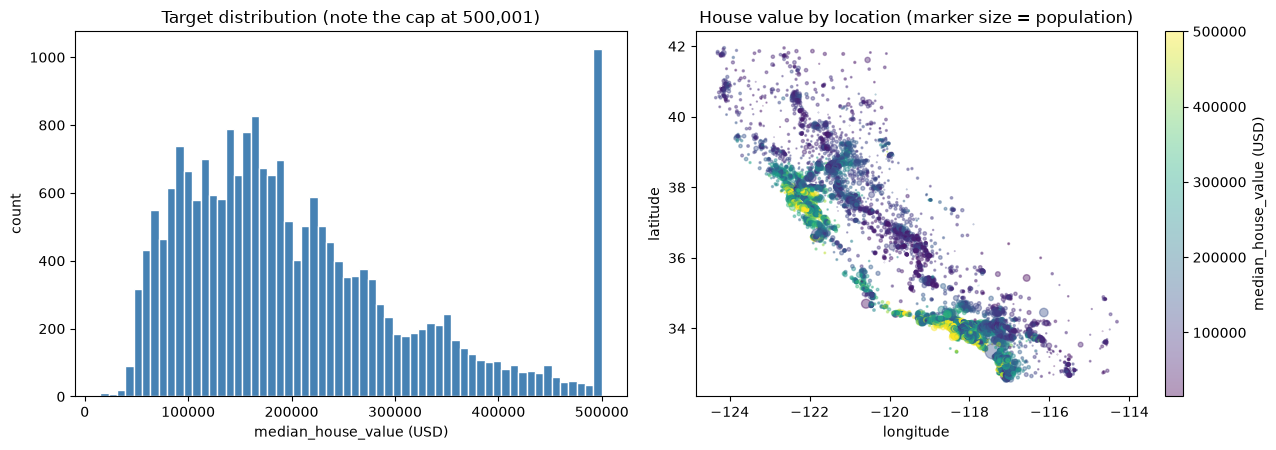

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(df['median_house_value'], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Target distribution (note the cap at 500,001)')
axes[0].set_xlabel('median_house_value (USD)'); axes[0].set_ylabel('count')

sc = axes[1].scatter(df.longitude, df.latitude, c=df.median_house_value, s=df.population / 300,
                     cmap='viridis', alpha=0.4)
plt.colorbar(sc, ax=axes[1], label='median_house_value (USD)')
axes[1].set_title('House value by location (marker size = population)')
axes[1].set_xlabel('longitude'); axes[1].set_ylabel('latitude')
plt.tight_layout(); plt.savefig('figures/reg_eda.png', dpi=130); plt.show()

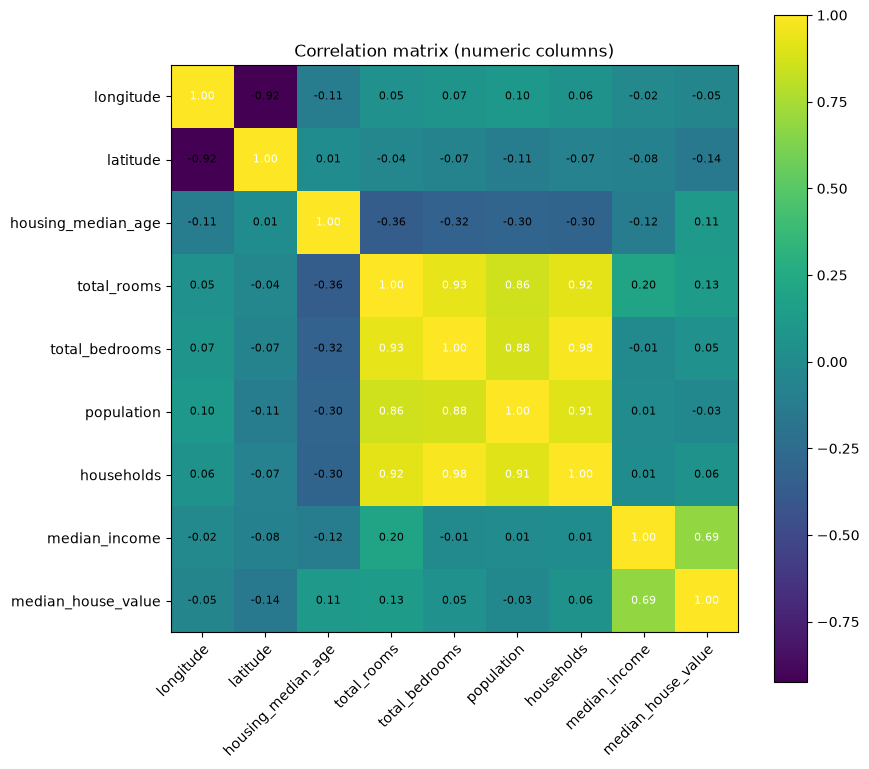

Correlation with the target:
median_income         0.6881
total_rooms           0.1342
housing_median_age    0.1056
households            0.0658
total_bedrooms        0.0497
population           -0.0246
longitude            -0.0460
latitude             -0.1442
Name: median_house_value, dtype: float64


In [8]:
num_cols = list(df.select_dtypes('number').columns)
corr = np.corrcoef(df[num_cols].dropna().values.T)
fig, ax = heatmap(corr, row_names=num_cols, column_names=num_cols, figsize=(9, 8), cell_font_size=8)
plt.title('Correlation matrix (numeric columns)')
plt.tight_layout(); plt.savefig('figures/reg_corr.png', dpi=130); plt.show()

print('Correlation with the target:')
print(df[num_cols].corr()['median_house_value'].drop('median_house_value').sort_values(ascending=False))

**Observations**
* `median_income` is by far the strongest single predictor (r ≈ 0.69).
* `total_rooms`, `total_bedrooms`, `population`, `households` are raw *counts* that scale with block size; they are heavily right-skewed and correlated with each other (r > 0.85), so ratios and log transforms are more informative than the raw counts.
* `total_bedrooms` has 207 missing values, and `ocean_proximity` is categorical (ISLAND has only 5 rows).
* The target is capped at 500,001 USD, which limits how well any model can fit the most expensive districts.

## 3. Preprocessing and feature engineering

* `ocean_proximity` → one-hot (5 columns, fixed order so the web app can reproduce it).
* Split 70 / 15 / 15 into train / validation / test **before** imputing, so no test information leaks into training.
* Impute `total_bedrooms` with the **training** median.
* Feature engineering is written in PyTorch and runs *inside* the model, so the ONNX file accepts the 13 raw inputs:
  `log1p` of the four count columns, plus `rooms_per_household`, `bedrooms_per_room`, `population_per_household`.
* Continuous features are standardized with training means / standard deviations (stored as model buffers).
  One-hot columns are left as 0/1, because standardizing the 5-row ISLAND column would turn it into a value near 60.
* The target is standardized for training; the model also returns the de-scaled prediction in USD.

In [9]:
CATEGORIES = ['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN']
NUMERIC    = ['longitude', 'latitude', 'housing_median_age', 'total_rooms',
              'total_bedrooms', 'population', 'households', 'median_income']
INPUT_FEATURES = NUMERIC + ['ocean_' + c for c in CATEGORIES]     ## 13 raw inputs (ONNX input order)
TARGET = 'median_house_value'

data = df.copy()
for c in CATEGORIES:
    data['ocean_' + c] = (data['ocean_proximity'] == c).astype(np.float32)

X = data[INPUT_FEATURES].values.astype(np.float32)
y = data[[TARGET]].values.astype(np.float32)

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_val,   X_test, y_val, y_test  = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED)

bed_idx = INPUT_FEATURES.index('total_bedrooms')
BED_MEDIAN = float(np.nanmedian(X_train[:, bed_idx]))
for arr in (X_train, X_val, X_test):
    arr[np.isnan(arr[:, bed_idx]), bed_idx] = BED_MEDIAN

print('train', X_train.shape, '| val', X_val.shape, '| test', X_test.shape)
print('total_bedrooms imputed with training median =', BED_MEDIAN)

train (14448, 13) | val (3096, 13) | test (3096, 13)
total_bedrooms imputed with training median = 437.0


In [10]:
ENGINEERED = ['longitude', 'latitude', 'housing_median_age',
              'log_total_rooms', 'log_total_bedrooms', 'log_population', 'log_households',
              'median_income', 'log_rooms_per_household', 'bedrooms_per_room', 'log_population_per_household'] \
             + ['ocean_' + c for c in CATEGORIES]
N_FEAT = len(ENGINEERED)          ## 16 engineered features
N_CONT = 11                       ## first 11 are continuous, last 5 are one-hot

def engineer_features(x):
    """x: raw inputs [N, 13] in INPUT_FEATURES order -> engineered features [N, 16]."""
    lon, lat, age = x[:, 0:1], x[:, 1:2], x[:, 2:3]
    rooms, beds, pop, hh, inc = x[:, 3:4], x[:, 4:5], x[:, 5:6], x[:, 6:7], x[:, 7:8]
    onehot = x[:, 8:13]
    rooms_pos = torch.clamp(rooms, min=1.0)
    hh_pos    = torch.clamp(hh,    min=1.0)
    feats = [lon, lat, age,
             torch.log1p(torch.clamp(rooms, min=0.0)), torch.log1p(torch.clamp(beds, min=0.0)),
             torch.log1p(torch.clamp(pop,   min=0.0)), torch.log1p(torch.clamp(hh,   min=0.0)),
             inc,
             torch.log1p(rooms_pos / hh_pos),
             torch.clamp(torch.clamp(beds, min=0.0) / rooms_pos, max=1.0),   ## a share, so at most 1
             torch.log1p(torch.clamp(pop, min=0.0) / hh_pos),
             onehot]
    return torch.cat(feats, dim=1)

X_train_tr, X_val_tr, X_test_tr = map(torch.tensor, (X_train, X_val, X_test))
y_train_tr, y_val_tr, y_test_tr = map(torch.tensor, (y_train, y_val, y_test))

## scaling statistics from the TRAINING set only (epsilon as in the class utils)
epsilon = 0.0001
Z_train = engineer_features(X_train_tr)
x_means      = Z_train.mean(0, keepdim=True)
x_deviations = Z_train.std(0, keepdim=True) + epsilon
x_means[:, N_CONT:] = 0.0          ## leave one-hot columns as 0/1
x_deviations[:, N_CONT:] = 1.0

y_means      = y_train_tr.mean(0, keepdim=True)
y_deviations = y_train_tr.std(0, keepdim=True) + epsilon
y_train_scaled = (y_train_tr - y_means) / y_deviations
y_val_scaled   = (y_val_tr   - y_means) / y_deviations

pd.DataFrame(Z_train.numpy(), columns=ENGINEERED).describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
longitude,-119.5841,2.0029,-124.3500,-114.3100
latitude,35.6507,2.1357,32.5500,41.9500
housing_median_age,28.5754,12.6136,1.0000,52.0000
log_total_rooms,7.6336,0.7516,1.0986,10.3929
log_total_bedrooms,6.0586,0.7279,0.6931,8.7712
log_population,7.0278,0.7366,1.3863,10.4824
log_households,5.9876,0.7287,0.6931,8.7133
median_income,3.8769,1.9049,0.4999,15.0001
log_rooms_per_household,1.8299,0.2331,0.6360,4.9622
bedrooms_per_room,0.2131,0.0584,0.1000,1.0000


In [11]:
BATCH_SIZE = 64
train_ds = TensorDataset(X_train_tr, y_train_scaled)
train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True)

## 4. Models (all PyTorch)

| # | Model | Idea |
|---|---|---|
| 1 | `LinearRegressionNet` | single `nn.Linear` — ordinary linear regression trained by gradient descent |
| 2 | `MLP` | one hidden layer (64, ReLU) |
| 3 | `DeepNN` | three hidden layers (128 → 64 → 32, ReLU, dropout 0.1) |
| 4 | `F1plusF2` | class model: linear part F1 + nonlinear part F2 (sigmoid hidden layer, dropout 0.25) |
| 5 | `ResidualNet` | class model: two 64-unit ReLU layers with a projected skip connection |

Every model inherits from `ScaledRegressor`, which applies feature engineering + standardization on the way in and de-scaling on the way out, and returns `(y_descaled, y_scaled)` like the class example.

In [12]:
class ScaledRegressor(nn.Module):
    def __init__(self, x_means, x_deviations, y_means, y_deviations):
        super().__init__()
        self.register_buffer('x_means', x_means.clone())
        self.register_buffer('x_deviations', x_deviations.clone())
        self.register_buffer('y_means', y_means.clone())
        self.register_buffer('y_deviations', y_deviations.clone())

    def core(self, z):
        raise NotImplementedError

    def forward(self, x):
        z = (engineer_features(x) - self.x_means) / self.x_deviations
        y_scaled = self.core(z)
        y_descaled = y_scaled * self.y_deviations + self.y_means
        return y_descaled, y_scaled


class LinearRegressionNet(ScaledRegressor):
    def __init__(self, *stats):
        super().__init__(*stats)
        self.linear1 = nn.Linear(N_FEAT, 1)
    def core(self, z):
        return self.linear1(z)


class MLP(ScaledRegressor):
    def __init__(self, *stats, hidden=64):
        super().__init__(*stats)
        self.net = nn.Sequential(nn.Linear(N_FEAT, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def core(self, z):
        return self.net(z)


class DeepNN(ScaledRegressor):
    def __init__(self, *stats, dropout_rate=0.1):
        super().__init__(*stats)
        self.net = nn.Sequential(
            nn.Linear(N_FEAT, 128), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(128, 64),     nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(64, 32),      nn.ReLU(),
            nn.Linear(32, 1))
    def core(self, z):
        return self.net(z)


class F1plusF2(ScaledRegressor):
    ## Linear (F1) + Nonlinear (F2), as in the class example
    def __init__(self, *stats, hidden=32):
        super().__init__(*stats)
        self.f1_linear1 = nn.Linear(N_FEAT, 1)
        self.f2_linear1 = nn.Linear(N_FEAT, hidden)
        self.f2_act1    = nn.Sigmoid()
        self.f2_dropout = nn.Dropout(0.25)
        self.f2_linear2 = nn.Linear(hidden, 1)
    def core(self, z):
        f1 = self.f1_linear1(z)
        f2 = self.f2_linear2(self.f2_dropout(self.f2_act1(self.f2_linear1(z))))
        return f1 + f2


class ResidualNet(ScaledRegressor):
    ## residual network from the class example
    def __init__(self, *stats, hidden=64, dropout_rate=0.1):
        super().__init__(*stats)
        self.fc1 = nn.Linear(N_FEAT, hidden); self.act1 = nn.ReLU(); self.dropout1 = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden, hidden); self.act2 = nn.ReLU(); self.dropout2 = nn.Dropout(dropout_rate)
        self.fc3 = nn.Linear(hidden, 1)
        self.input_proj = nn.Linear(N_FEAT, hidden)
    def core(self, z):
        x0 = self.input_proj(z)
        x1 = self.dropout1(self.act1(self.fc1(z)))
        x2 = self.dropout2(self.act2(self.fc2(x1)))
        return self.fc3(x2 + x0)

## 5. Training

Adam (lr = 0.001), MSE on the standardized target, mini-batches of 64, up to 300 epochs with **early stopping**: training stops when validation loss has not improved for 25 epochs, and the best-validation weights are restored.

In [13]:
loss_fn = nn.MSELoss()

def train_model(model, train_dl, X_val_tr, y_val_scaled, n_epochs=300, lr=0.001, patience=25, verbose_every=25):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    Xv, yv = X_val_tr.to(device), y_val_scaled.to(device)
    history = {'train': [], 'val': []}
    best_val, best_state, bad_epochs = float('inf'), None, 0
    for epoch in range(n_epochs):
        model.train()
        running = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            _, pred_scaled = model(xb)
            loss = loss_fn(pred_scaled, yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(train_dl.dataset)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv)[1], yv).item()
        history['train'].append(train_loss); history['val'].append(val_loss)
        if val_loss < best_val - 1e-5:
            best_val, best_state, bad_epochs = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
        if epoch % verbose_every == 0:
            print(f'  epoch {epoch:3d} | train {train_loss:.4f} | val {val_loss:.4f}')
        if bad_epochs >= patience:
            print(f'  early stop at epoch {epoch}, best val loss {best_val:.4f}')
            break
    model.load_state_dict(best_state)
    model.eval()
    return model, history


def predict_usd(model, X_tr):
    model.eval()
    with torch.no_grad():
        return model(X_tr.to(device))[0].cpu().numpy()


def regression_metrics(y_true, y_pred):
    return {'R2':   r2_score(y_true, y_pred),
            'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
            'MAE':  mean_absolute_error(y_true, y_pred)}

In [14]:
stats = (x_means, x_deviations, y_means, y_deviations)
model_builders = {
    'LinearRegressionNet': lambda: LinearRegressionNet(*stats),
    'MLP':                 lambda: MLP(*stats),
    'DeepNN':              lambda: DeepNN(*stats),
    'F1plusF2':            lambda: F1plusF2(*stats),
    'ResidualNet':         lambda: ResidualNet(*stats),
}

models, histories, rows = {}, {}, []
for name, build in model_builders.items():
    set_seed()
    print(f'=== {name} ===')
    t0 = time.time()
    model, hist = train_model(build(), train_dl, X_val_tr, y_val_scaled)
    secs = time.time() - t0
    models[name], histories[name] = model, hist
    n_params = sum(p.numel() for p in model.parameters())
    m_tr = regression_metrics(y_train, predict_usd(model, X_train_tr))
    m_va = regression_metrics(y_val,   predict_usd(model, X_val_tr))
    m_te = regression_metrics(y_test,  predict_usd(model, X_test_tr))
    rows.append({'model': name, 'params': n_params, 'epochs': len(hist['val']), 'train_s': secs,
                 'train_R2': m_tr['R2'], 'val_R2': m_va['R2'], 'test_R2': m_te['R2'],
                 'test_RMSE': m_te['RMSE'], 'test_MAE': m_te['MAE']})
    print(f'  -> val R2 {m_va["R2"]:.4f} | test R2 {m_te["R2"]:.4f} | {secs:.0f}s\n')

=== LinearRegressionNet ===


  epoch   0 | train 0.9062 | val 0.6175


  epoch  25 | train 0.3300 | val 0.3601


  epoch  50 | train 0.3285 | val 0.3592


  epoch  75 | train 0.3275 | val 0.3586


  epoch 100 | train 0.3268 | val 0.3585


... (33 outputs left out)

  epoch 100 | train 0.1803 | val 0.2070


  epoch 125 | train 0.1742 | val 0.2056


  epoch 150 | train 0.1711 | val 0.2001


  early stop at epoch 173, best val loss 0.1993
  -> val R2 0.7950 | test R2 0.8199 | 44s



## 6. Results and comparison

In [15]:
results = pd.DataFrame(rows).sort_values('val_R2', ascending=False).reset_index(drop=True)
results

,model,params,epochs,train_s,train_R2,val_R2,test_R2,test_RMSE,test_MAE
0,ResidualNet,6401,174,43.6796,0.8491,0.7950,0.8199,"48,803.3441","33,446.4609"
1,DeepNN,12545,106,31.5500,0.8686,0.7927,0.8136,"49,650.1089","33,992.3867"
2,MLP,1153,109,19.3519,0.8147,0.7712,0.7986,"51,609.9711","36,268.7383"
3,F1plusF2,594,300,58.6520,0.7673,0.7382,0.7685,"55,333.4965","39,070.8984"
4,LinearRegressionNet,17,222,30.4434,0.6759,0.6337,0.6635,"66,706.7306","48,135.1406"


In [16]:
BEST_NAME  = results.loc[0, 'model']          ## chosen on VALIDATION R2, reported on TEST
best_model = models[BEST_NAME]
print('Best model (by validation R2):', BEST_NAME)
print(results.loc[0, ['val_R2', 'test_R2', 'test_RMSE', 'test_MAE']])

Best model (by validation R2): ResidualNet
val_R2           0.7950
test_R2          0.8199
test_RMSE   48,803.3441
test_MAE    33,446.4609
Name: 0, dtype: float64


In [17]:
## Reference point only (not PyTorch): a gradient-boosted tree model on the same engineered features
from sklearn.ensemble import HistGradientBoostingRegressor
Z_tr, Z_te = engineer_features(X_train_tr).numpy(), engineer_features(X_test_tr).numpy()
hgb = HistGradientBoostingRegressor(random_state=SEED).fit(Z_tr, y_train.ravel())
ref = regression_metrics(y_test, hgb.predict(Z_te))
print('HistGradientBoosting reference -> test R2 %.4f | RMSE %.0f | MAE %.0f' % (ref['R2'], ref['RMSE'], ref['MAE']))

HistGradientBoosting reference -> test R2 0.8502 | RMSE 44499 | MAE 30496


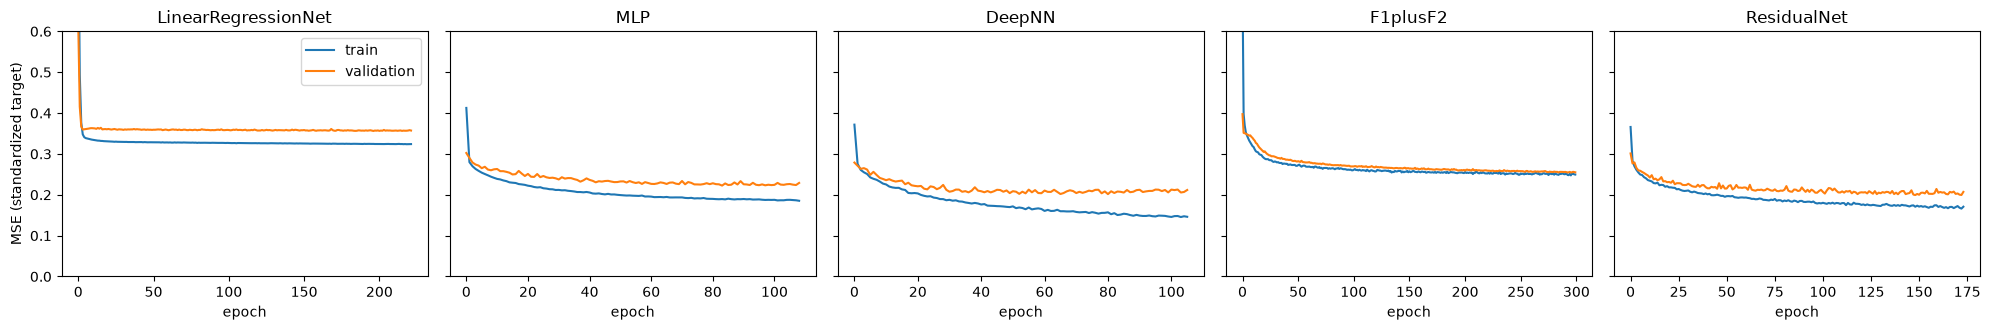

In [18]:
fig, axes = plt.subplots(1, len(histories), figsize=(4 * len(histories), 3.4), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h['train'], label='train'); ax.plot(h['val'], label='validation')
    ax.set_title(name); ax.set_xlabel('epoch'); ax.set_ylim(0, 0.6)
axes[0].set_ylabel('MSE (standardized target)'); axes[0].legend()
plt.tight_layout(); plt.savefig('figures/reg_learning_curves.png', dpi=130); plt.show()

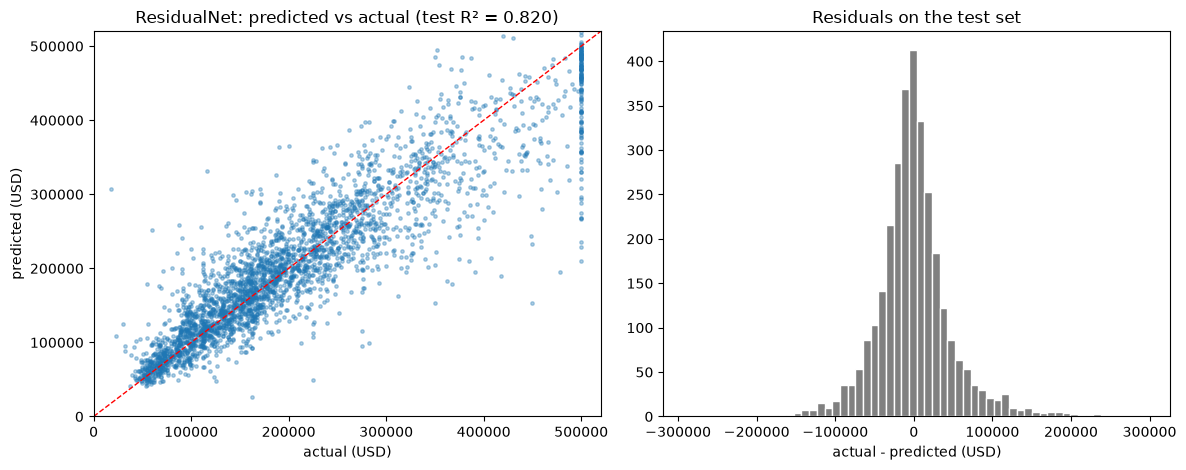

Capped test rows: 141 of 3096
MAE on uncapped rows: 31,785 USD | MAE on capped rows: 68,268 USD
Mean residual on capped rows: 67,624 USD (positive = the model under-predicts them)


In [19]:
y_pred_best = predict_usd(best_model, X_test_tr)
resid = y_test.ravel() - y_pred_best.ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(y_test, y_pred_best, s=6, alpha=0.35)
lims = [0, 520000]
axes[0].plot(lims, lims, 'r--', lw=1)
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel('actual (USD)'); axes[0].set_ylabel('predicted (USD)')
axes[0].set_title(f'{BEST_NAME}: predicted vs actual (test R² = {r2_score(y_test, y_pred_best):.3f})')
axes[1].hist(resid, bins=60, color='gray', edgecolor='white')
axes[1].set_title('Residuals on the test set'); axes[1].set_xlabel('actual - predicted (USD)')
plt.tight_layout(); plt.savefig('figures/reg_pred_vs_actual.png', dpi=130); plt.show()

capped = y_test.ravel() >= 500000
print(f'Capped test rows: {capped.sum()} of {len(capped)}')
print(f'MAE on uncapped rows: {np.abs(resid[~capped]).mean():,.0f} USD | MAE on capped rows: {np.abs(resid[capped]).mean():,.0f} USD')
print(f'Mean residual on capped rows: {resid[capped].mean():,.0f} USD (positive = the model under-predicts them)')

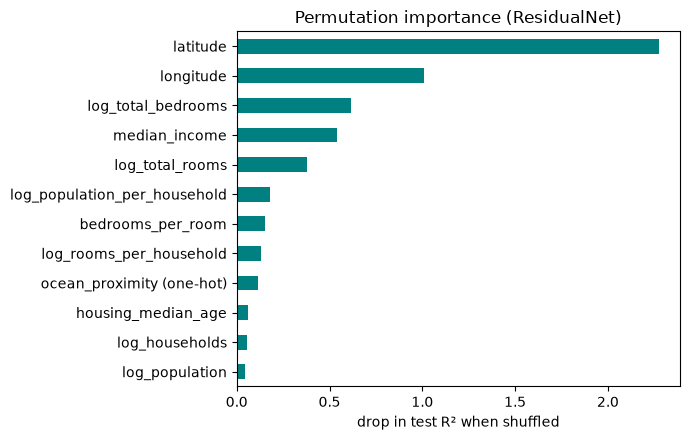

latitude                       2.2748
longitude                      1.0080
log_total_bedrooms             0.6176
median_income                  0.5421
log_total_rooms                0.3781
log_population_per_household   0.1768
bedrooms_per_room              0.1511
log_rooms_per_household        0.1282
ocean_proximity (one-hot)      0.1124
housing_median_age             0.0603
log_households                 0.0573
log_population                 0.0425
dtype: float64

In [20]:
## Permutation importance of the ENGINEERED features for the best model:
## shuffle one standardized feature (one-hot columns as one group) and measure the drop in test R2.
## (Shuffling raw total_rooms or total_bedrooms alone would create impossible bedroom/room ratios.)
rng = np.random.default_rng(SEED)
with torch.no_grad():
    Z_test = ((engineer_features(X_test_tr) - best_model.x_means) / best_model.x_deviations).to(device)
def r2_from_z(Z):
    with torch.no_grad():
        yp = (best_model.core(Z) * best_model.y_deviations + best_model.y_means).cpu().numpy()
    return r2_score(y_test, yp)
base_r2 = r2_from_z(Z_test)
groups = {f: [i] for i, f in enumerate(ENGINEERED[:N_CONT])}
groups['ocean_proximity (one-hot)'] = list(range(N_CONT, N_FEAT))
imp = {}
for g, idx in groups.items():
    drops = []
    for _ in range(5):
        Zp = Z_test.clone()
        perm = torch.tensor(rng.permutation(len(Zp)))
        Zp[:, idx] = Z_test[perm][:, idx]
        drops.append(base_r2 - r2_from_z(Zp))
    imp[g] = float(np.mean(drops))
imp = pd.Series(imp).sort_values()
imp.plot.barh(figsize=(7, 4.5), color='teal'); plt.xlabel('drop in test R² when shuffled')
plt.title(f'Permutation importance ({BEST_NAME})'); plt.tight_layout()
plt.savefig('figures/reg_importance.png', dpi=130); plt.show()
imp.sort_values(ascending=False)

## 7. Export the best model to ONNX

The export wrapper returns only the de-scaled prediction (USD), so the browser receives a ready-to-display number. Feature engineering and scaling are part of the graph, so the web page sends the 13 raw inputs in `INPUT_FEATURES` order.

In [21]:
class ExportWrapper(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        y_descaled, _ = self.m(x)
        return y_descaled

export_model = ExportWrapper(copy.deepcopy(best_model).to('cpu')).eval().float()
dummy_input = torch.randn(1, len(INPUT_FEATURES), dtype=torch.float32).abs() * 10
ONNX_PATH = 'ONNXmodels/housing_regressor.onnx'

torch.onnx.export(
    export_model,
    dummy_input,
    ONNX_PATH,
    input_names=['input1'],
    output_names=['output1'],
    opset_version=15,                 ## fine for onnxruntime-web
    do_constant_folding=True,
    dynamic_axes={'input1': {0: 'batch'}, 'output1': {0: 'batch'}},
    dynamo=False,                     ## classic exporter, same as the class example
)
print('ONNX model saved:', ONNX_PATH, f'({os.path.getsize(ONNX_PATH)/1024:.1f} KB)')

ONNX model saved: ONNXmodels/housing_regressor.onnx (33.5 KB)


/tmp/ipykernel_713/3268451048.py:12: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [22]:
## Verify: ONNX Runtime must reproduce the PyTorch predictions
sess = rt.InferenceSession(ONNX_PATH)
print('inputs :', [(i.name, i.shape) for i in sess.get_inputs()])
print('outputs:', [(o.name, o.shape) for o in sess.get_outputs()])
onnx_pred = sess.run(['output1'], {'input1': X_test.astype(np.float32)})[0]
print('max |ONNX - PyTorch| =', np.abs(onnx_pred - y_pred_best).max(), 'USD')
print('ONNX test R2 =', r2_score(y_test, onnx_pred))

inputs : [('input1', ['batch', 13])]
outputs: [('output1', ['batch', 1])]
max |ONNX - PyTorch| = 0.15625 USD
ONNX test R2 = 0.8198784589767456


In [23]:
## A few test rows with their predictions, used to check the web page gives the same numbers
samples = []
for i in [0, 1, 2]:
    row = dict(zip(INPUT_FEATURES, X_test[i].tolist()))
    row['ocean_proximity'] = CATEGORIES[int(np.argmax(X_test[i, 8:13]))]
    samples.append({'inputs': row, 'actual': float(y_test[i, 0]), 'onnx_pred': float(onnx_pred[i, 0])})
    print(row['ocean_proximity'], '| actual', f'{y_test[i,0]:,.0f}', '| predicted', f'{onnx_pred[i,0]:,.0f}')

summary = {'best_model': BEST_NAME, 'input_features': INPUT_FEATURES, 'categories': CATEGORIES,
           'bedrooms_median': BED_MEDIAN, 'results': results.to_dict(orient='records'),
           'reference_hgb': ref, 'samples': samples,
           'capped_rows': int(capped.sum()), 'mae_uncapped': float(np.abs(resid[~capped]).mean()),
           'mae_capped': float(np.abs(resid[capped]).mean()), 'mean_resid_capped': float(resid[capped].mean()),
           'importance': imp.to_dict()}
with open('ONNXmodels/regression_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=float)
print('saved ONNXmodels/regression_summary.json')

INLAND | actual 100,000 | predicted 76,645
INLAND | actual 118,800 | predicted 109,054
<1H OCEAN | actual 376,100 | predicted 375,535
saved ONNXmodels/regression_summary.json
